# Chapter 00 - Background

## Example B.1 Cartesian to Polar Form

Express the following numbers in polar form:

(a)  2 + j3

(b) -2 + j1

(c) -2 - j3

(d)  1 - j3

### Solution formula B.1
$$z=a+jb \\ |z|=\sqrt{(a^2+b^2)} \\ \theta=atan2(b,a)$$

In [ ]:
import numpy as np

valores = np.array([2 + 3j, -2 + 1j, -2 - 3j, 1 - 3j])

modulos = np.abs(valores)
angulos = np.angle(valores) # em radianos

for item, z, modulo, angulo in zip("abcd", valores, modulos, angulos):
    # O ' g' (com espaço) deixa um espaço reservado para o sinal nos positivos
    cartesiana = f"{z.real: g}{z.imag:+g}j"
    print(
        f"({item}) {cartesiana:>6} = "
        f"|{modulo:.2f}| ∠ {np.degrees(angulo):.2f}°"
    )

(a)   2+3j = |3.61| ∠ 56.31°
(b)  -2+1j = |2.24| ∠ 153.43°
(c)  -2-3j = |3.61| ∠ -123.69°
(d)   1-3j = |3.16| ∠ -71.57°


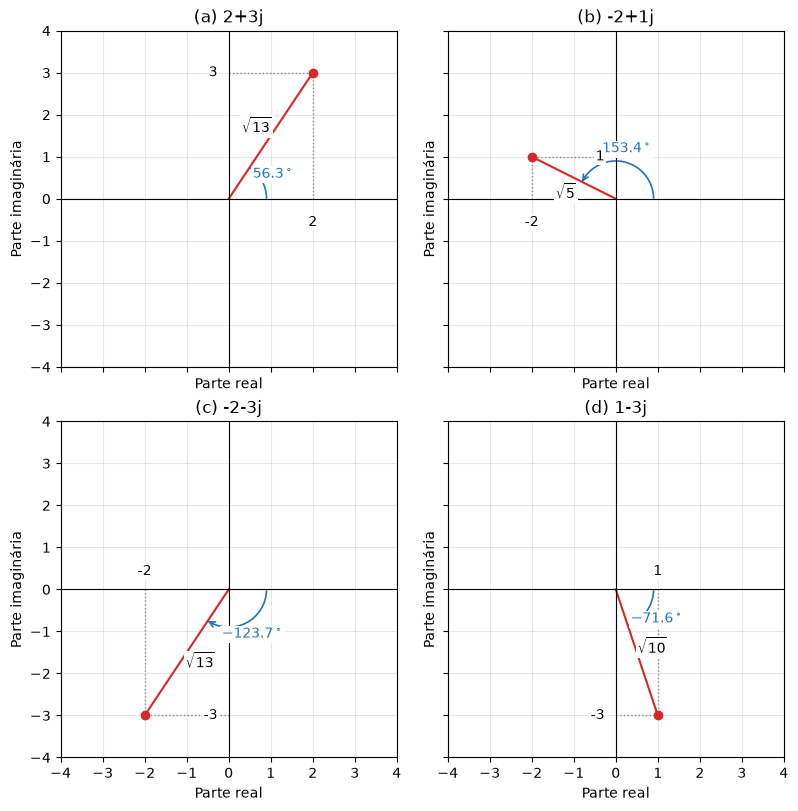

In [29]:
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

fig, axes = plt.subplots(
    2, 2, figsize=(8, 8), sharex=True, sharey=True,
    layout="constrained"
)

for item, z, angulo, ax in zip("abcd", valores, angulos, axes.flat):
    real, imag = z.real, z.imag
    modulo = np.abs(z)

    # Projecoes do ponto nos eixos real e imaginario.
    ax.plot([real, real], [0, imag], ":", color="0.55", linewidth=1)
    ax.plot([0, real], [imag, imag], ":", color="0.55", linewidth=1)

    ax.plot([0, real], [0, imag], color="tab:red")
    ax.plot(z.real, z.imag, "o", color="tab:red")

    # O modulo e o comprimento do segmento; neste exemplo, |z| = sqrt(a²+b²).
    quadrado_modulo = round(modulo ** 2)
    rotulo_modulo = rf"$\sqrt{{{quadrado_modulo}}}$"
    # Deslocamento perpendicular ao segmento para o texto nao cobrir a linha.
    normal = np.array([-imag, real]) / modulo
    ax.annotate(
        rotulo_modulo, xy=(real / 2, imag / 2),
        xytext=12 * normal, textcoords="offset points",
        ha="center", va="center",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "pad": 1
        },
    )
    # Arc recebe graus e desenha no sentido anti-horario.
    # Para angulos negativos, invertemos os limites do arco.
    graus = np.degrees(angulo)
    raio = 0.9
    inicio, fim = sorted((0, graus))
    ax.add_patch(Arc(
        (0, 0), 2 * raio, 2 * raio,
        theta1=inicio, 
        theta2=fim, 
        color="tab:blue", 
        linewidth=1.2,
    ))

    # A seta indica o sentido do angulo: positivo anti-horario,
    # negativo horario, sempre partindo do semieixo real positivo.
    antes = angulo - np.sign(angulo) * np.deg2rad(10)
    ax.annotate(
        "",
        xy=(raio * np.cos(angulo), raio * np.sin(angulo)),
        xytext=(raio * np.cos(antes), raio * np.sin(antes)),
        arrowprops={
            "arrowstyle": "->", 
            "color": "tab:blue",
            "lw": 1.2, 
            "shrinkA": 0, 
            "shrinkB": 0
        },
    )

    # Posiciona o valor proximo ao meio do arco.
    raio_texto = 1.35 * raio
    ax.text(
        raio_texto * np.cos(angulo / 2),
        raio_texto * np.sin(angulo / 2),
        rf"${graus:.1f}^\circ$",
        color="tab:blue", ha="center", va="center",
        bbox={
            "facecolor": "white", 
            "edgecolor": "none", 
            "pad": 1
        },
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)

    # Marca as coordenadas junto aos eixos que passam pela origem.
    ax.annotate(f"{real:g}", xy=(real, 0),
                xytext=(0, 8 if imag < 0 else -12),
                textcoords="offset points", ha="center",
                va="bottom" if imag < 0 else "top",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.annotate(f"{imag:g}", xy=(0, imag), xytext=(-8, 0),
                textcoords="offset points", ha="right", va="center",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

    ax.set(
        title=f"({item}) {z.real:g}{z.imag:+g}j",
        xlabel="Parte real",
        ylabel="Parte imaginária",
        xlim=(-4, 4),
        ylim=(-4, 4),
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

plt.show()

In [ ]:
import sympy as sym
from IPython.display import Math, display

componentes = [(2, 3), (-2, 1), (-2, -3), (1, -3)]

for real, imag in componentes:
    z = real + sym.I * imag
    modulo = sym.Abs(z)
    angulo = float(sym.arg(z) * 180 / sym.pi)

    display(Math(
        rf"{sym.latex(z)} \approx "
        rf"{sym.latex(modulo)}\,e^{{j({angulo:.2f}^\circ)}}"
    ))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Example B.2 Polar to Cartesian Form

Represents the following numbers in the complex plane and express them in Cartesian form.

(a) $2\,e^{j\pi/3}$

(b) $4\,e^{-j3\pi/4}$

(c) $2\,e^{j\pi/2}$

(d) $3\,e^{-j3\pi}$

(e) $2\,e^{j4\pi}$

(f) $2\,e^{-j4\pi}$

### Solution Formula B.2

The Cartesian form of a complex number $re^{j\theta}$ is given by:
$$re^{j\theta} = r(\cos\theta + j\sin\theta) = r\cos\theta + jr\sin\theta$$

In [37]:
import numpy as np

polares_b2 = np.array([
    (2, np.pi / 3),
    (4, -3 * np.pi / 4),
    (2, np.pi / 2),
    (3, -3 * np.pi),
    (2, 4 * np.pi),
    (2, -4 * np.pi),
])

modulos_b2 = polares_b2[:, 0]
angulos_b2 = polares_b2[:, 1]
# A sua formula de Euler, aplicada aos seis numeros de uma vez.
cartesianos_b2 = modulos_b2 * (np.cos(angulos_b2) + 1j * np.sin(angulos_b2))
# Equivalente: cartesianos_b2 = modulos_b2 * np.exp(1j * angulos_b2)

for item, z in zip("abcdef", cartesianos_b2):
    # Limpa residuos de ponto flutuante somente para a apresentacao.
    real = 0.0 if np.isclose(z.real, 0, atol=1e-12, rtol=0) else z.real
    imag = 0.0 if np.isclose(z.imag, 0, atol=1e-12, rtol=0) else z.imag
    print(f"({item}) {real: .2f} {imag:+.2f}j")


(a)  1.00 +1.73j
(b) -2.83 -2.83j
(c)  0.00 +2.00j
(d) -3.00 +0.00j
(e)  2.00 +0.00j
(f)  2.00 +0.00j


Os calculos usam radianos. Valores residuais proximos de zero sao efeitos de ponto flutuante; a limpeza acima afeta apenas a exibicao.


### Graphical solution B.2

Os angulos originais sao preservados. Para varias voltas, uma espiral indica o sentido e a quantidade de rotacao; seu raio nao representa o modulo do numero complexo.


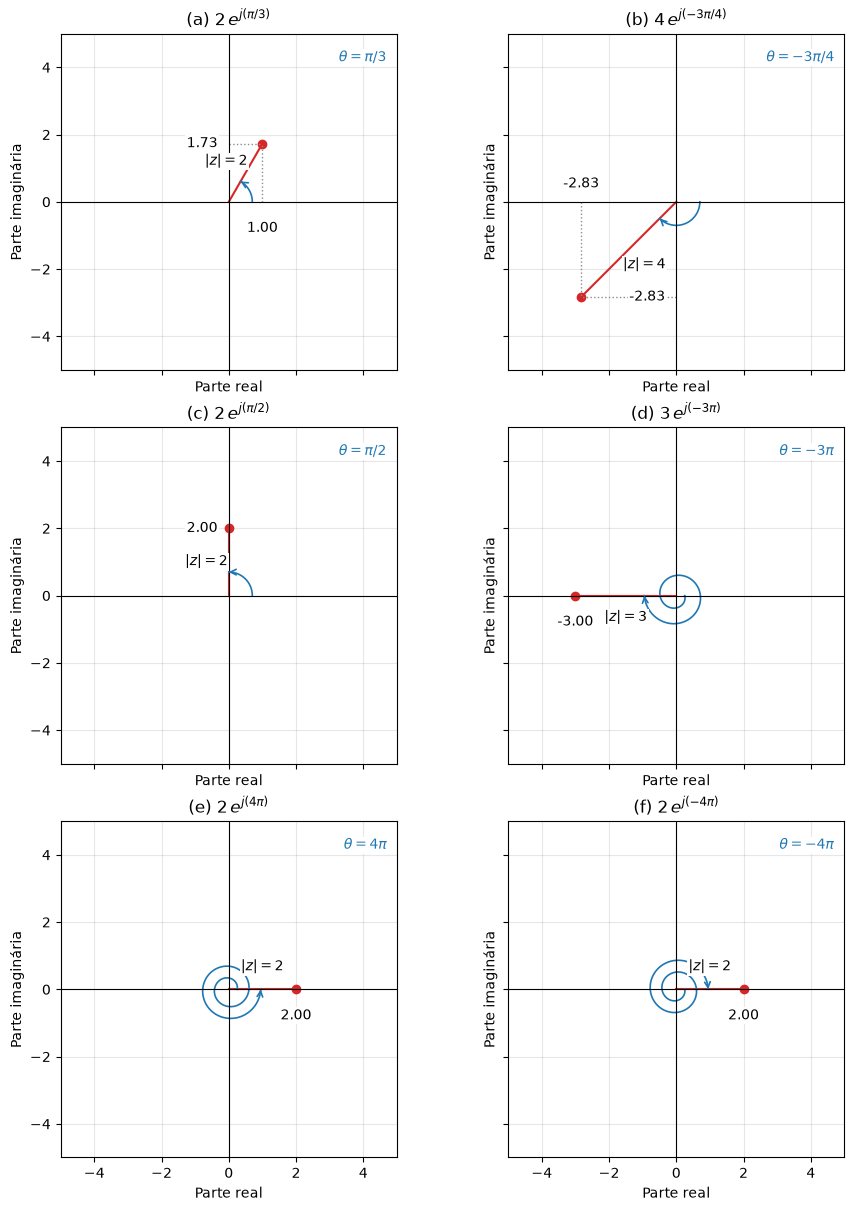

In [38]:
import matplotlib.pyplot as plt

rotulos_angulos_b2 = [r"\pi/3", r"-3\pi/4", r"\pi/2", r"-3\pi", r"4\pi", r"-4\pi"]
fig_b2, axes_b2 = plt.subplots(
    3, 2, figsize=(9, 12), sharex=True, sharey=True,
    layout="constrained",
)

for item, z, modulo, angulo, rotulo, ax in zip(
    "abcdef", cartesianos_b2, modulos_b2, angulos_b2,
    rotulos_angulos_b2, axes_b2.flat,
):
    real = 0.0 if np.isclose(z.real, 0, atol=1e-12, rtol=0) else z.real
    imag = 0.0 if np.isclose(z.imag, 0, atol=1e-12, rtol=0) else z.imag

    ax.plot([0, real], [0, imag], color="tab:red")
    ax.plot(real, imag, "o", color="tab:red")
    # Quando o ponto ja esta sobre um eixo, as projecoes sao dispensaveis.
    if real != 0 and imag != 0:
        ax.plot([real, real], [0, imag], ":", color="0.55", linewidth=1)
        ax.plot([0, real], [imag, imag], ":", color="0.55", linewidth=1)
    if real != 0:
        ax.annotate(f"{real:.2f}", xy=(real, 0),
                    xytext=(0, 8 if imag < 0 else -14),
                    textcoords="offset points", ha="center",
                    va="bottom" if imag < 0 else "top",
                    bbox={"facecolor":"white", "edgecolor":"none", "pad":1})
    if imag != 0:
        ax.annotate(f"{imag:.2f}", xy=(0, imag), xytext=(-8, 0),
                    textcoords="offset points", ha="right", va="center",
                    bbox={"facecolor":"white", "edgecolor":"none", "pad":1})

    normal = np.array([-imag, real]) / modulo
    ax.annotate(rf"$|z|={modulo:g}$", xy=(real / 2, imag / 2),
                xytext=16 * normal, textcoords="offset points",
                ha="center", va="center",
                bbox={"facecolor":"white", "edgecolor":"none", "pad":1})

    # O angulo dado pode conter varias voltas. Um raio crescente separa
    # visualmente essas voltas; a espiral representa a rotacao, nao o modulo.
    t = np.linspace(0, angulo, 500)
    raios = np.linspace(0.25, 0.95, t.size) if abs(angulo) > 2 * np.pi else np.full(t.size, 0.7)
    x_arco, y_arco = raios * np.cos(t), raios * np.sin(t)
    ax.plot(x_arco, y_arco, color="tab:blue", linewidth=1.2)
    ax.annotate(
        "", 
        xy=(x_arco[-1], y_arco[-1]),
        xytext=(x_arco[-5], y_arco[-5]),
        arrowprops={
            "arrowstyle":"->",
            "color":"tab:blue",
            "lw":1.2,
            "shrinkA":0,
            "shrinkB":0
        }
    )
    # Uma legenda fixa evita que o texto cubra as varias voltas.
    ax.text(0.97, 0.95, rf"$\theta={rotulo}$", transform=ax.transAxes,
            color="tab:blue", ha="right", va="top",
            bbox={"facecolor":"white", "edgecolor":"none", "pad":1})

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=rf"({item}) ${modulo:g}\,e^{{j({rotulo})}}$",
           xlabel="Parte real", ylabel="Parte imaginária",
           xlim=(-5, 5), ylim=(-5, 5))
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

plt.show()

### Symbolic solution B.2

Usamos multiplos exatos de `sym.pi` para obter a forma cartesiana sem aproximacoes numericas.


In [39]:
import sympy as sym
from IPython.display import Math, display

# sym.pi mantem os angulos exatos; nao convertemos os floats do NumPy.
polares_exatos_b2 = [
    (2, sym.pi / 3),
    (4, -3 * sym.pi / 4),
    (2, sym.pi / 2),
    (3, -3 * sym.pi),
    (2, 4 * sym.pi),
    (2, -4 * sym.pi),
]
cartesianos_exatos_b2 = []

for item, (modulo, angulo) in zip("abcdef", polares_exatos_b2):
    z_exato = sym.simplify(sym.expand_complex(modulo * sym.exp(sym.I * angulo)))
    cartesianos_exatos_b2.append(z_exato)
    # Montamos o lado polar como texto para preservar as voltas do enunciado.
    polar = rf"{modulo}\,e^{{j\left({sym.latex(angulo)}\right)}}"
    cartesiana = sym.latex(z_exato, imaginary_unit="j")
    display(Math(rf"\text{{({item})}}\quad {polar} = {cartesiana}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Example B.3 Multiplication and Division Of Complex Numbers

Using both polar and Cartesian forms, determine $z_1z_2$ and $ z_1 / z_2 $ for the numbers.

$$ z_1 = 3 + j4 = 5e^{j53.13^\circ} $$
and
$$ z_2 = 2 + j3 = \sqrt{13}e^{j56.31^\circ} $$

Multiplication of Complex Numbers in Cartesian Form:
$$z_1 z_2 = (3 + 4j)(2 + 3j) = (6-12) + j(8+9) = -6 + j17$$
Division of Complex Numbers in Cartesian Form:
$$\frac{z_1}{z_2} = \frac{3 + 4j}{2 + 3j} = \frac{(3 + 4j)(2 - 3j)}{(2 + 3j)(2 - 3j)} = \frac{6 - 9j + 8j - 12j^2}{2^2 + 3^2} = \frac{6 - j + 12}{13} = \frac{18}{13} - j\frac{1}{13} = 1.3846 - 0.0769j$$

In [26]:
# Example B.3 Multiplication and Division Of Complex Numbers in Cartesian Form

# cartesian form using python built-in complex numbers
z1 = 3 + 4j
z2 = 2 + 3j

print("Cartesian form calculations:")

# multiplication in cartesian form
z1z2 = z1 * z2
print(f"z1 * z2 (cartesian) = {z1z2}")

# division in cartesian form
z1_div_z2 = z1 / z2
print(f"z1 / z2 (cartesian) = {z1_div_z2:2f}")

Cartesian form calculations:
z1 * z2 (cartesian) = (-6+17j)
z1 / z2 (cartesian) = 1.384615-0.076923j


In [ ]:
import sympy as sym
from IPython.display import Math, display

# Usamos sym.I para preservar os valores exatos.
z1_exato_b3 = 3 + 4 * sym.I
z2_exato_b3 = 2 + 3 * sym.I

# Calculos na forma cartesiana.
produto_exato_b3 = sym.expand(z1_exato_b3 * z2_exato_b3)
quociente_exato_b3 = sym.simplify(sym.expand_complex(z1_exato_b3 / z2_exato_b3))


for operacao, resultado in [
    (r"z_1 z_2", produto_exato_b3),
    (r"\frac{z_1}{z_2}", quociente_exato_b3),
]:
    display(Math(rf"{operacao} = {sym.latex(resultado, imaginary_unit='j')}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Multiplication of Complex Numbers in Polar Form:
$$ z_1z_2 = (5e^{j53.1\circ})(\sqrt{13}e^{j56.3\circ}) = 5\sqrt{13}e^{j109.4\circ} $$
Division of Complex Numbers in Polar Form:
$$ \frac{z_1}{z_2} = \frac{5e^{j53.1\circ}}{\sqrt{13}e^{j56.3\circ}} = \frac{5}{\sqrt{13}}e^{j(53.1\circ - 56.3\circ)} = \frac{5}{\sqrt{13}}e^{-j3.2\circ} $$

In [ ]:
import numpy as np

# Example B.3 Multiplication and Division Of Complex Numbers in Polar Form

# polar form
(z1_mod, z1_deg) = (np.abs(z1), np.degrees(np.angle(z1)))
(z2_mod, z2_deg) = (np.abs(z2), np.degrees(np.angle(z2)))

print("Polar form calculations:")

# multiplication in polar form
z1z2_polar = (z1_mod * z2_mod, z1_deg + z2_deg)
print(f"z1 * z2 (polar) = |{z1z2_polar[0]:2f}| ∠ {z1z2_polar[1]:2f}°")

# division in polar form
z1_div_z2_polar = (z1_mod / z2_mod, z1_deg - z2_deg)
print(f"z1 / z2 (polar) = |{z1_div_z2_polar[0]:2f}| ∠ {z1_div_z2_polar[1]:2f}°")

Polar form calculations:
z1 * z2 (polar) = |18.027756| ∠ 109.440035°
z1 / z2 (polar) = |1.386750| ∠ -3.179830°


In [ ]:
import sympy as sym
from IPython.display import Math, display

# Forma polar: modulos e angulos exatos em radianos.
modulo1_b3, angulo1_b3 = sym.Integer(5), sym.atan(sym.Rational(4, 3))
modulo2_b3, angulo2_b3 = sym.sqrt(13), sym.atan(sym.Rational(3, 2))

produto_polar_exato_b3 = (
    sym.simplify(modulo1_b3 * modulo2_b3),
    sym.simplify(angulo1_b3 + angulo2_b3),
)
quociente_polar_exato_b3 = (
    sym.simplify(modulo1_b3 / modulo2_b3),
    sym.simplify(angulo1_b3 - angulo2_b3),
)

# Produto: multiplicamos os modulos e somamos os angulos.
# Quociente: dividimos os modulos e subtraimos os angulos.
for operacao, (modulo, angulo) in [
    (r"z_1 z_2", produto_polar_exato_b3),
    (r"\frac{z_1}{z_2}", quociente_polar_exato_b3),
]:
    # Aproximamos apenas o angulo exibido, convertido para graus.
    angulo_graus = float(angulo * 180 / sym.pi)
    display(Math(
        rf"{operacao} \approx {sym.latex(modulo)}"
        rf"\,e^{{j\left({angulo_graus:.2f}^\circ\right)}}"
    ))


<IPython.core.display.Math object>

<IPython.core.display.Math object>